In [1]:
import numpy as np
import matplotlib.pyplot as plt
from funkcije import expm_rk4

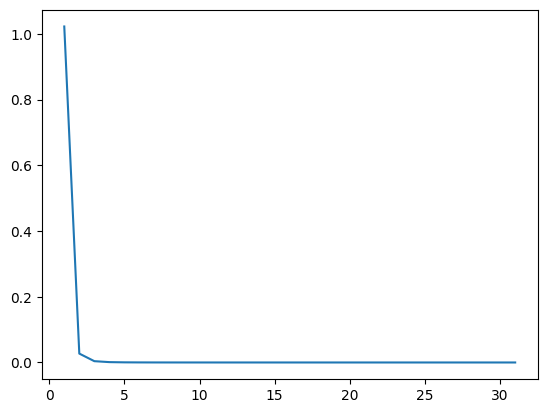

In [3]:
A = np.array([
    [-1, 1],
    [0, -2]
    ])
v = np.transpose([0, 1])
t = 1.0
s = [i for i in range(1, 32)]

y_nums = []
for i in s:
    y_nums.append(expm_rk4(A, v, t, steps=i))
y_ref = np.array([np.exp(-t) - np.exp(-2 * t), np.exp(-2 * t)])

rel_err = [np.linalg.norm(y_num - y_ref) / np.linalg.norm(y_ref) for y_num in y_nums]

plt.plot(
        s, rel_err
        )


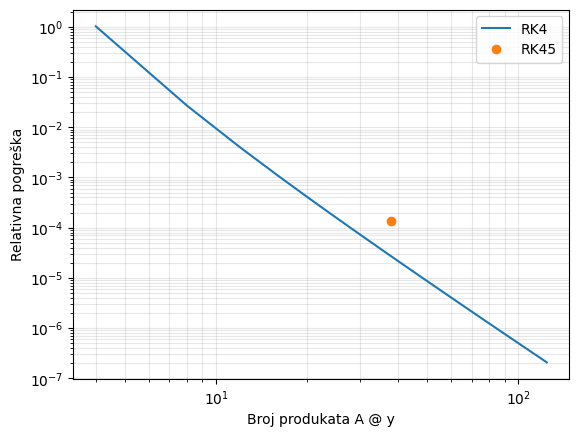

In [ ]:
from scipy.integrate import solve_ivp

rk45_cost = []
rk45_errors = []

for rtol in [1e-3, 1e-4, 1e-5, 1e-6, 1e-7]:
    sol = solve_ivp(
        lambda tau, y: A @ y,
        (0, t), v,
        method="RK45",
        rtol=rtol,
        atol=rtol / 100,
    )
    if not sol.success:
        raise RuntimeError(sol.message)

    y_rk45 = sol.y[:, -1]
    error = np.linalg.norm(y_rk45 - y_ref) / np.linalg.norm(y_ref)
    rk45_cost.append(sol.nfev)
    rk45_errors.append(error)

plt.figure()
plt.loglog(4 * np.array(s), rel_err, label="RK4")
plt.loglog(rk45_cost, rk45_errors, "o-", label="RK45")
plt.xlabel("Broj produkata Ay")
plt.ylabel("Relativna pogreška")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()